In [1]:
%pip install -q -U ultralytics roboflow python-dotenv


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 59.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 8.8 MB/s eta 0:00:00


In [2]:
from roboflow import Roboflow
from ultralytics import YOLO
from getpass import getpass
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

api_key = getpass("Pega la API key de Roboflow del profesor: ").strip()

if not api_key:
    raise ValueError("Debes ingresar la API key.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Pega la API key de Roboflow del profesor: ··········


In [3]:
rf = Roboflow(api_key=api_key)

project = rf.workspace("semilleroml").project("sitesafety-pbakq")
dataset = project.version(1).download("yolo26")

print(f"Dataset descargado en: {dataset.location}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SiteSafety-1 in yolo26:: 100%|██████████| 23/23 [00:00<00:00, 2519.43it/s]

Dataset descargado en: /content/SiteSafety-1


In [4]:
model = YOLO("yolo26n.pt")

results = model.train(
    data=str(Path(dataset.location) / "data.yaml"),
    epochs=20,
)

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SiteSafety-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opti

In [5]:
best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"

if not best_weights.exists():
    raise FileNotFoundError(
        f"No se encontraron los pesos entrenados: {best_weights}"
    )

model = YOLO(str(best_weights))

test_dir = Path(dataset.location) / "test" / "images"

test_images = sorted(
    path
    for path in test_dir.glob("*")
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if not test_images:
    raise FileNotFoundError(
        f"No se encontraron imágenes de prueba en: {test_dir}"
    )

image_path = str(test_images[0])

print(f"Usando imagen de prueba: {image_path}")

# Conservamos los parámetros del notebook original.
resultados = model(
    image_path,
    conf=0.001,
    iou=0.7,
)

Usando imagen de prueba: /content/SiteSafety-1/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg

image 1/1 /content/SiteSafety-1/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg: 640x640 17 helmets, 283 vests, 182.5ms
Speed: 4.7ms preprocess, 182.5ms inference, 18.6ms postprocess per image at shape (1, 3, 640, 640)


In [6]:
r = resultados[0]

print("=== Información general ===")
print(f"Imagen original: {r.path}")
print(f"Tamaño original (alto, ancho): {r.orig_shape}")
print(f"Objetos detectados: {len(r.boxes)}")

print("\n=== Detecciones ===")

for i, box in enumerate(r.boxes):
    clase_id = int(box.cls[0])
    clase_nombre = r.names[clase_id]
    confianza = float(box.conf[0])
    x1, y1, x2, y2 = box.xyxy[0].tolist()

    print(
        f"[{i + 1}] {clase_nombre} | "
        f"confianza: {confianza:.4f} | "
        f"bbox: ({x1:.0f}, {y1:.0f}) → ({x2:.0f}, {y2:.0f})"
    )

=== Información general ===
Imagen original: /content/SiteSafety-1/test/images/00596_jpg.rf.069990c2f14e9a321e05f3d069869555.jpg
Tamaño original (alto, ancho): (640, 640)
Objetos detectados: 300

=== Detecciones ===
[1] vest | confianza: 0.8533 | bbox: (198, 321) → (312, 578)
[2] vest | confianza: 0.6899 | bbox: (200, 400) → (313, 565)
[3] vest | confianza: 0.6290 | bbox: (103, 420) → (209, 640)
[4] vest | confianza: 0.5828 | bbox: (193, 377) → (322, 640)
[5] vest | confianza: 0.5658 | bbox: (347, 352) → (462, 640)
[6] vest | confianza: 0.5280 | bbox: (46, 367) → (156, 640)
[7] vest | confianza: 0.4491 | bbox: (94, 382) → (173, 640)
[8] vest | confianza: 0.4236 | bbox: (224, 307) → (306, 581)
[9] vest | confianza: 0.4217 | bbox: (216, 505) → (316, 640)
[10] vest | confianza: 0.4111 | bbox: (63, 397) → (180, 640)
[11] vest | confianza: 0.4066 | bbox: (203, 453) → (319, 640)
[12] vest | confianza: 0.3897 | bbox: (195, 350) → (299, 554)
[13] vest | confianza: 0.3667 | bbox: (209, 209) → (

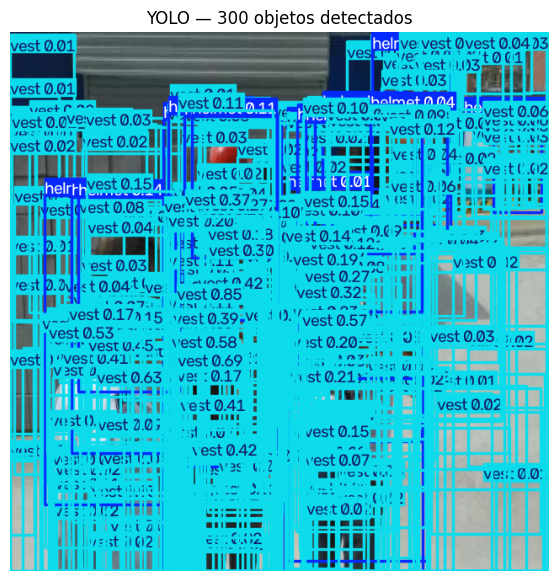

In [7]:
imagen_anotada = r.plot()
imagen_anotada_rgb = imagen_anotada[:, :, ::-1]

plt.figure(figsize=(12, 7))
plt.imshow(imagen_anotada_rgb)
plt.title(f"YOLO — {len(r.boxes)} objetos detectados")
plt.axis("off")
plt.show()